# SFA

## Importing libraries

In [1]:
# Data handling and manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt

# Statistical modeling and optimization
import statsmodels.api as sm
import optbinning as optb

# Metrics
from sklearn.metrics import roc_auc_score

# Serialization and deserialization
import pickle

## Importing development data

In [2]:
riskdiff_data = pd.read_csv("Data/riskdiff_data.csv")

In [3]:
train = riskdiff_data[riskdiff_data["port_type"] == "DEV"].copy()

In [4]:
dictionary = pd.read_csv("Data/data_dictionary.csv")

In [5]:
dictionary

,variable,group,availability,description
0,customer_id,observation_status,quarterly/current,customer id
1,quarter,observation_status,quarterly/current,quarter
2,observation_date,observation_status,quarterly/current,observation date
3,core_customer,observation_status,quarterly/current,core customer
4,sector,behavior_macro_or_ratios,quarterly/current,sector
...,...,...,...,...
123,debt_ke_growth_yoy,accounting_report,"annual, lagged",debt ke growth yoy
124,cash_ke_growth_yoy,accounting_report,"annual, lagged",cash ke growth yoy
125,equity_ke_growth_yoy,accounting_report,"annual, lagged",equity ke growth yoy
126,default_12m,target,Never use as predictor,default 12m


In [6]:
var = dictionary[np.isin(dictionary["group"], ["behavior_macro_or_ratios"])]["variable"].tolist()

In [7]:
train_info = pd.DataFrame([train[var].dtypes.astype(str), train[var].isna().sum().astype(np.int64)], index=['dtypes', 'na_count']).T
display(train_info)

,dtypes,na_count
sector,str,0
customer_age_years,float64,0
relationship_age_quarters,int64,0
credit_limit_ke,float64,0
ead_ke,float64,0
...,...,...
credit_limit_to_revenue,float64,2134
overdraft_to_limit,float64,0
cashflow_in_to_out,float64,0
cash_to_ead,float64,0


relationship_age_quarters
Gini coefficient: 0.26418033250218254


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 5.50)",2473,0.168748,2430,43,0.017388,0.818052,0.078825,0.009587
1,"[5.50, 11.50)",2476,0.168953,2401,75,0.030291,0.249758,0.009406,0.001173
2,"[11.50, 27.50)",4430,0.302286,4204,226,0.051016,-0.293138,0.029792,0.003711
3,"[27.50, 31.50)",893,0.060935,817,76,0.085106,-0.841489,0.064398,0.007820
4,"[31.50, 37.50)",1140,0.077789,1075,65,0.057018,-0.410706,0.015914,0.001975
5,"[37.50, inf)",3243,0.221290,3163,80,0.024669,0.460855,0.038201,0.004733
6,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
7,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.236537,0.029000


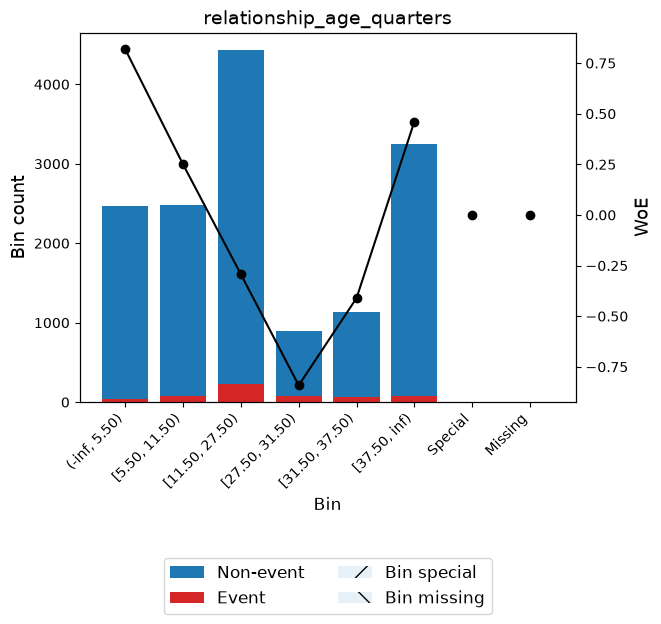

utilization_pct
Gini coefficient: 0.32498677904997586


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 50.01)",3408,0.232549,3358,50,0.014671,0.990683,0.148434,0.017831
1,"[50.01, 60.31)",3964,0.270488,3859,105,0.026488,0.387808,0.034143,0.004241
2,"[60.31, 71.66)",4107,0.280246,3943,164,0.039932,-0.036564,0.000381,0.000048
3,"[71.66, 83.67)",2427,0.165609,2253,174,0.071693,-0.655432,0.097046,0.011918
4,"[83.67, inf)",749,0.051109,677,72,0.096128,-0.97539,0.077432,0.009313
5,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
6,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.357435,0.043351


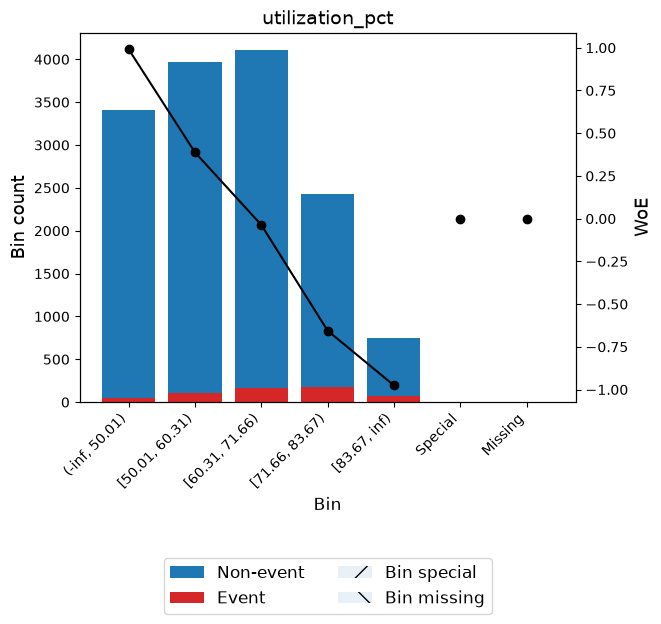

arrears_amount_ke
Gini coefficient: 0.19755955708247241


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 5.65)",4792,0.326987,4683,109,0.022746,0.543951,0.075850,0.009366
1,"[5.65, 36.21)",4843,0.330467,4666,177,0.036548,0.055513,0.000993,0.000124
2,"[36.21, inf)",5020,0.342545,4741,279,0.055578,-0.383603,0.060351,0.007498
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.137194,0.016988


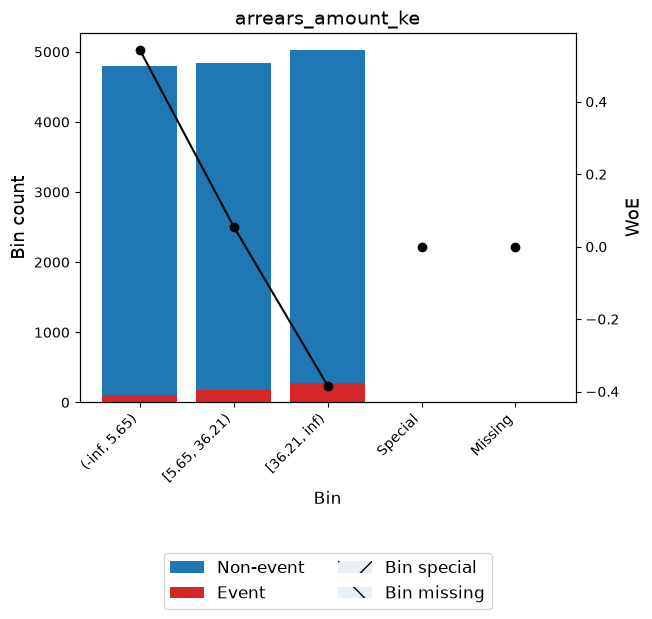

days_past_due_proxy
Gini coefficient: 0.26370023301531864


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 3.86)",7044,0.480655,6888,156,0.022147,0.571285,0.121542,0.014989
1,"[3.86, 9.97)",3355,0.228932,3228,127,0.037854,0.019036,0.000082,0.000010
2,"[9.97, inf)",4256,0.290413,3974,282,0.066259,-0.570774,0.123898,0.015280
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.245522,0.030280


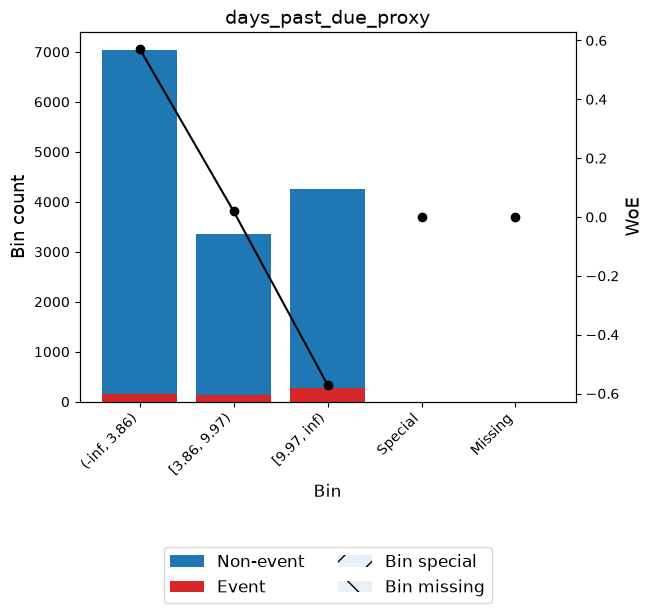

missed_payments_12m
Gini coefficient: 0.12750899715482644


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.50)",11679,0.796929,11298,381,0.032623,0.173187,0.022083,0.002757
1,"[0.50, inf)",2976,0.203071,2792,184,0.061828,-0.496817,0.063349,0.007838
2,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
3,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.085432,0.010595


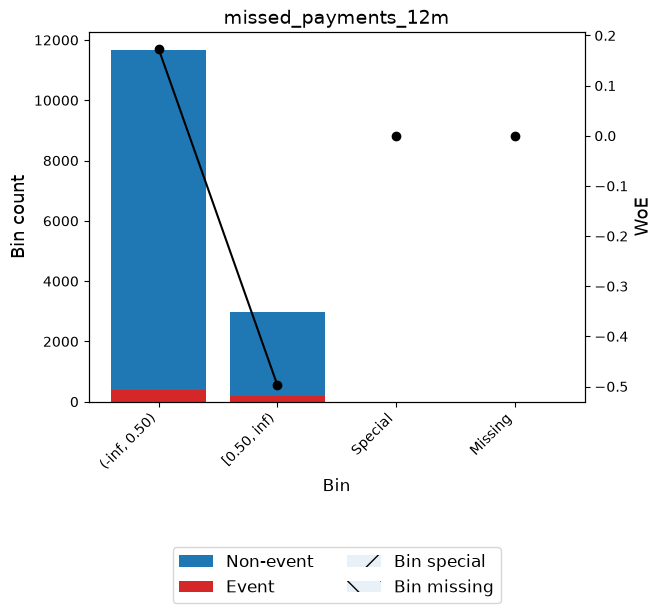

max_utilization_12m_pct
Gini coefficient: 0.30628362549225274


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 60.96)",4742,0.323576,4662,80,0.016871,0.848778,0.160657,0.019500
1,"[60.96, 76.46)",5781,0.394473,5582,199,0.034423,0.117603,0.005169,0.000646
2,"[76.46, 83.37)",1969,0.134357,1857,112,0.056882,-0.408176,0.027117,0.003366
3,"[83.37, inf)",2163,0.147595,1989,174,0.080444,-0.780063,0.130115,0.015864
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.323058,0.039376


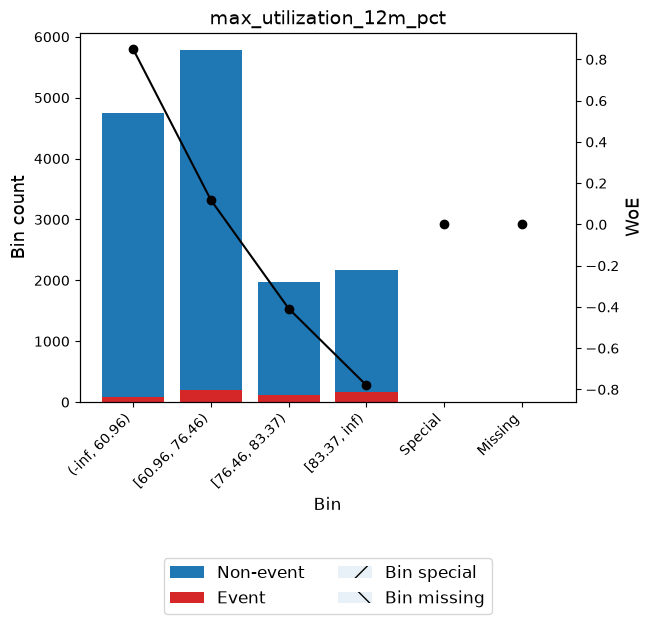

payment_delay_avg_days
Gini coefficient: 0.2474270963527765


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 4.31)",3892,0.265575,3821,71,0.018243,0.769193,0.111934,0.013657
1,"[4.31, 8.10)",2764,0.188605,2689,75,0.027135,0.363042,0.021093,0.002622
2,"[8.10, 13.51)",2151,0.146776,2066,85,0.039517,-0.025676,0.000098,0.000012
3,"[13.51, inf)",5483,0.374139,5164,319,0.058180,-0.432119,0.085603,0.010618
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,365,0.024906,350,15,0.041096,-0.066512,0.000114,0.000014
Totals,,14655,1.000000,14090,565,0.038553,,0.218842,0.026923


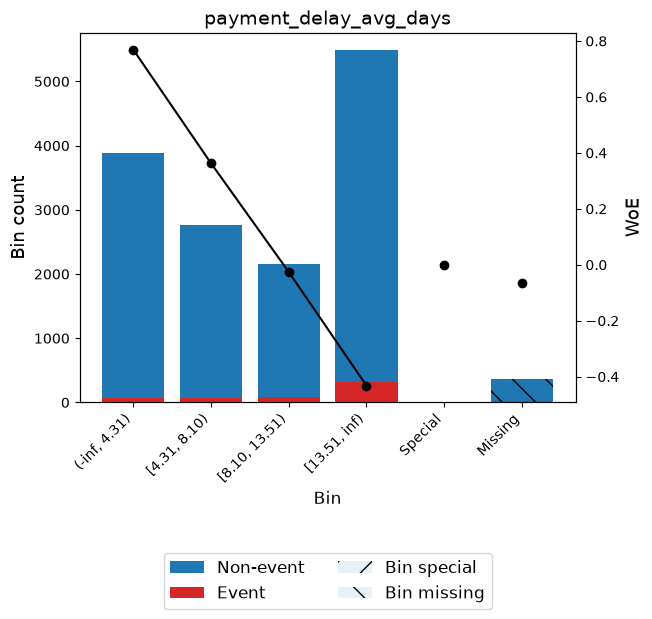

payment_delay_max_days
Gini coefficient: 0.2528884478416249


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 18.13)",5265,0.359263,5161,104,0.019753,0.6881,0.125384,0.015371
1,"[18.13, 34.86)",2928,0.199795,2825,103,0.035178,0.09514,0.001731,0.000216
2,"[34.86, 66.41)",4203,0.286796,3998,205,0.048775,-0.245855,0.019443,0.002424
3,"[66.41, inf)",2259,0.154145,2106,153,0.067729,-0.594287,0.072104,0.008883
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.218662,0.026894


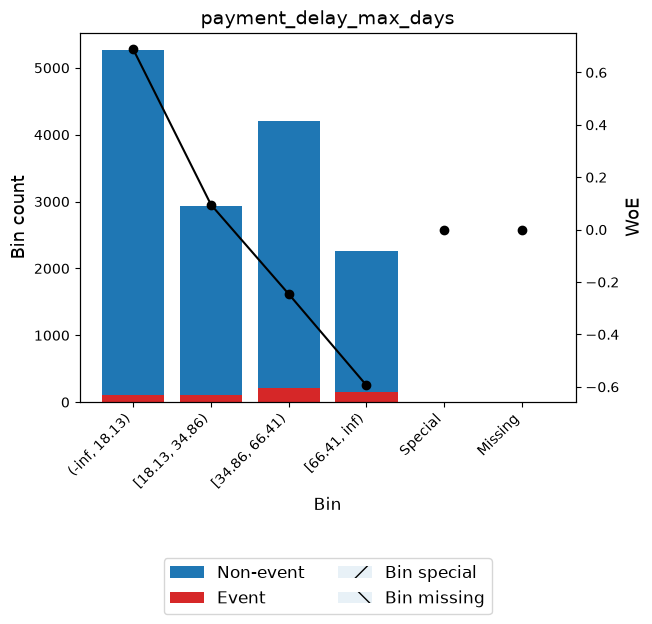

external_delinquency_count
Gini coefficient: 0.12859945860052635


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.50)",9264,0.632139,8971,293,0.031628,0.205185,0.024234,0.003024
1,"[0.50, inf)",4529,0.309041,4285,244,0.053875,-0.350687,0.044797,0.005571
2,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
3,Missing,862,0.058820,834,28,0.032483,0.177634,0.001711,0.000214
Totals,,14655,1.000000,14090,565,0.038553,,0.070743,0.008809


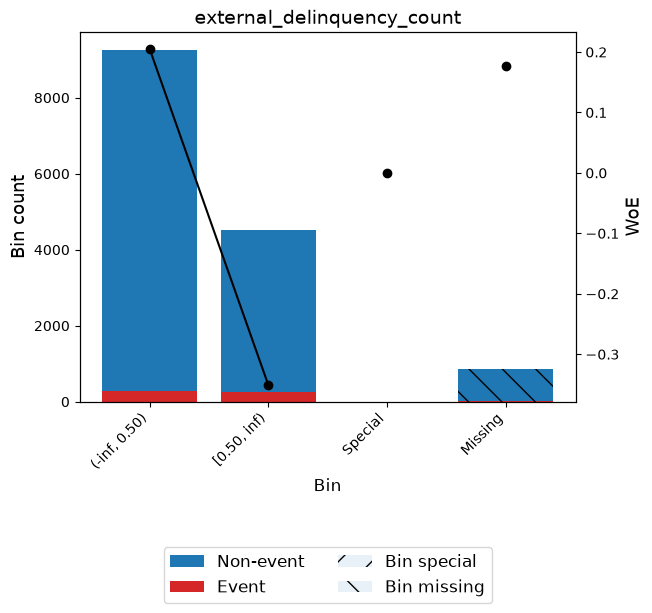

external_payment_index
Gini coefficient: 0.2738029230546988


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 35.67)",901,0.061481,829,72,0.079911,-0.772841,0.053015,0.006467
1,"[35.67, 59.26)",4053,0.276561,3809,244,0.060202,-0.468441,0.075665,0.009373
2,"[59.26, 73.01)",3122,0.213033,3011,111,0.035554,0.084102,0.001450,0.000181
3,"[73.01, inf)",5694,0.388536,5579,115,0.020197,0.665438,0.128040,0.015716
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,885,0.060389,862,23,0.025989,0.407366,0.008339,0.001035
Totals,,14655,1.000000,14090,565,0.038553,,0.266509,0.032772


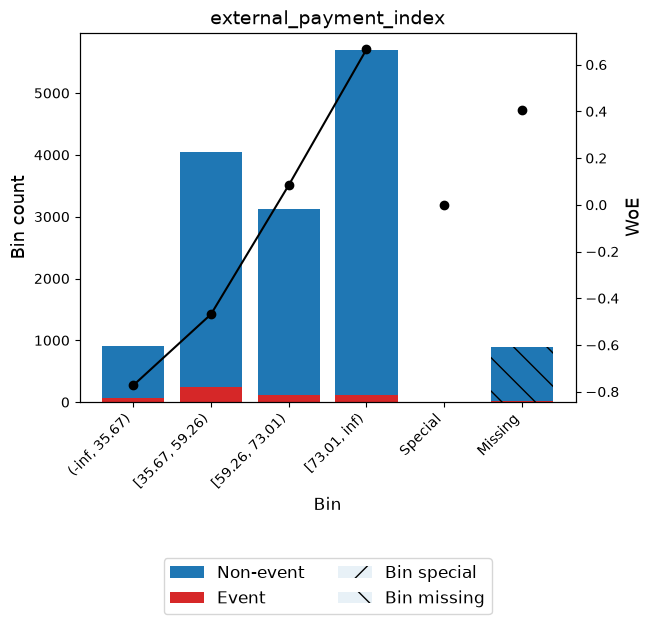

deposit_volatility_12m
Gini coefficient: 0.32014483378031233


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.03)",762,0.051996,759,3,0.003937,2.316995,0.112509,0.011577
1,"[0.03, 0.18)",5540,0.378028,5418,122,0.022022,0.577066,0.097293,0.011996
2,"[0.18, 0.26)",3022,0.206209,2916,106,0.035076,0.098134,0.001898,0.000237
3,"[0.26, 0.34)",2636,0.179870,2503,133,0.050455,-0.281499,0.016258,0.002026
4,"[0.34, 0.41)",1504,0.102627,1396,108,0.071809,-0.65716,0.060507,0.007430
5,"[0.41, inf)",807,0.055067,725,82,0.101611,-1.036942,0.097139,0.011626
6,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
7,Missing,384,0.026203,373,11,0.028646,0.307288,0.002152,0.000268
Totals,,14655,1.000000,14090,565,0.038553,,0.387755,0.045159


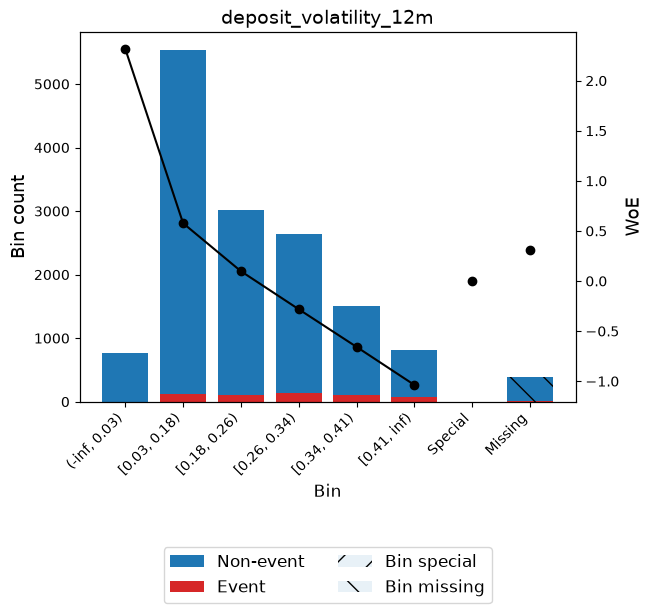

days_since_last_payment
Gini coefficient: 0.10416023414585118


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.31)",864,0.058956,827,37,0.042824,-0.109508,0.000744,0.000093
1,"[0.31, 0.70)",1071,0.073081,1046,25,0.023343,0.517458,0.015518,0.001918
2,"[0.70, 8.97)",10000,0.682361,9644,356,0.035600,0.082766,0.004500,0.000562
3,"[8.97, inf)",2720,0.185602,2573,147,0.054044,-0.354,0.027458,0.003414
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.048220,0.005988


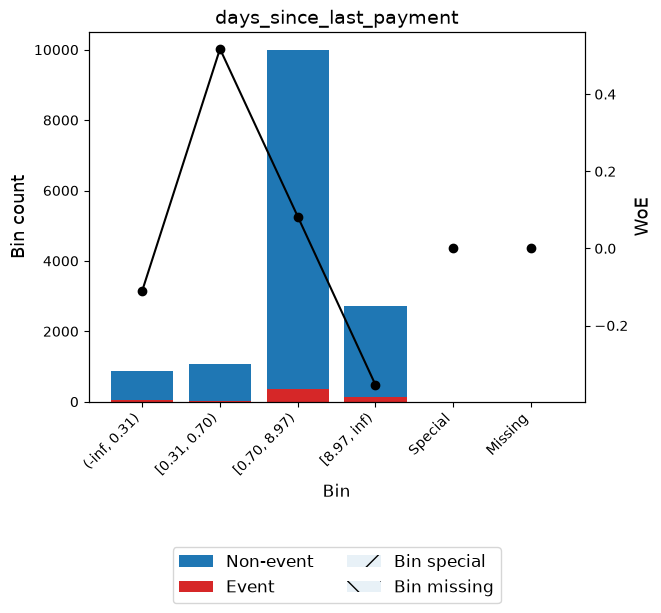

cash_flow_stress_score
Gini coefficient: 0.32454750434940993


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -0.87)",1155,0.078813,1149,6,0.005195,2.038493,0.144586,0.015477
1,"[-0.87, 0.87)",7270,0.496076,7093,177,0.024347,0.474319,0.090183,0.011168
2,"[0.87, 1.51)",2400,0.163767,2295,105,0.043750,-0.131867,0.003028,0.000378
3,"[1.51, 2.47)",2757,0.188127,2579,178,0.064563,-0.543021,0.071682,0.008852
4,"[2.47, inf)",1073,0.073217,974,99,0.092265,-0.930103,0.098679,0.011909
5,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
6,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.408158,0.047784


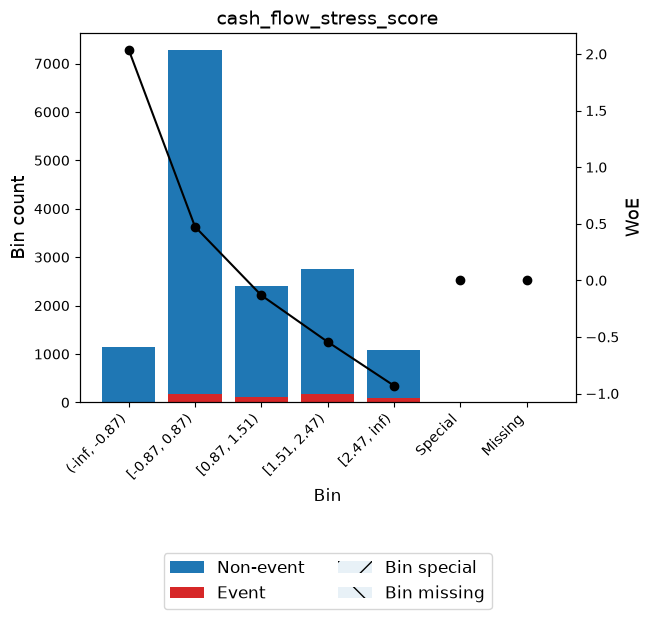

gross_margin_behavior_proxy
Gini coefficient: 0.24034782717925873


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.01)",1607,0.109655,1475,132,0.082141,-0.802784,0.103514,0.012603
1,"[0.01, 0.05)",3282,0.223951,3126,156,0.047532,-0.218741,0.011866,0.001480
2,"[0.05, 0.10)",4340,0.296145,4189,151,0.034793,0.106543,0.003201,0.000400
3,"[0.10, inf)",5426,0.370249,5300,126,0.023222,0.522785,0.080062,0.009895
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.198643,0.024378


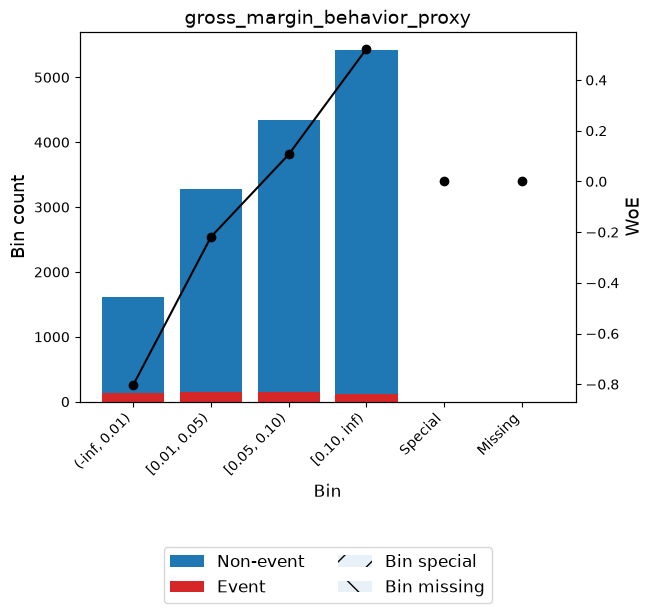

gdp_yoy_proxy_pct
Gini coefficient: 0.33727390919311384


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.00)",3017,0.205868,2773,244,0.080875,-0.785878,0.184722,0.022514
1,"[0.00, 0.80)",1236,0.084340,1163,73,0.059061,-0.448096,0.020909,0.002592
2,"[0.80, 2.01)",5633,0.384374,5464,169,0.030002,0.259643,0.023025,0.002870
3,"[2.01, inf)",4769,0.325418,4690,79,0.016565,0.867345,0.167430,0.020296
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.396086,0.048272


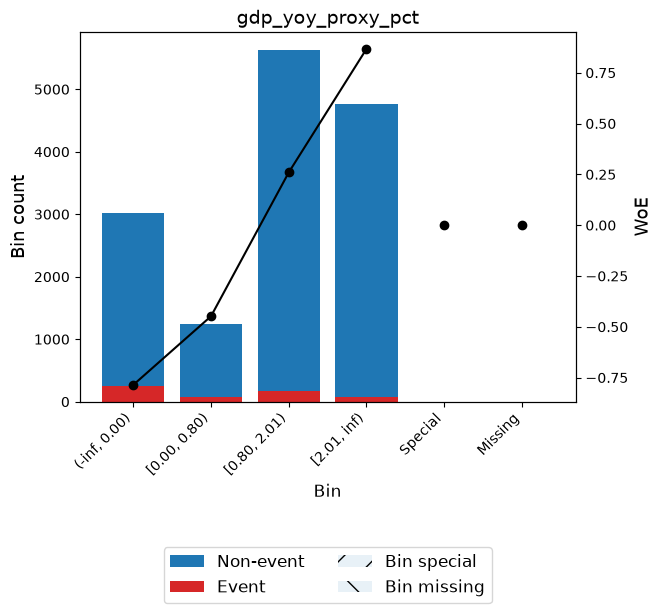

unemployment_proxy_pct
Gini coefficient: 0.22387320449449488


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 7.59)",1122,0.076561,1106,16,0.014260,1.019522,0.051156,0.006131
1,"[7.59, 8.51)",4081,0.278472,3977,104,0.025484,0.427497,0.041974,0.005207
2,"[8.51, 11.32)",7034,0.479973,6761,273,0.038811,-0.006941,0.000023,0.000003
3,"[11.32, inf)",2418,0.164995,2246,172,0.071133,-0.646983,0.093826,0.011528
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.186980,0.022869


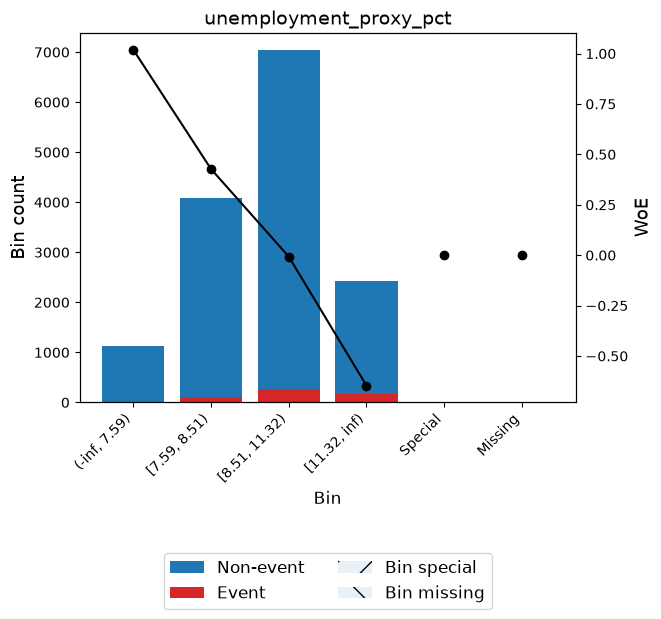

interest_rate_proxy_pct
Gini coefficient: 0.14786674789752374


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.88)",4781,0.326237,4677,104,0.021753,0.589626,0.087186,0.010743
1,"[0.88, inf)",9874,0.673763,9413,461,0.046688,-0.199946,0.029565,0.003690
2,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
3,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.116751,0.014433


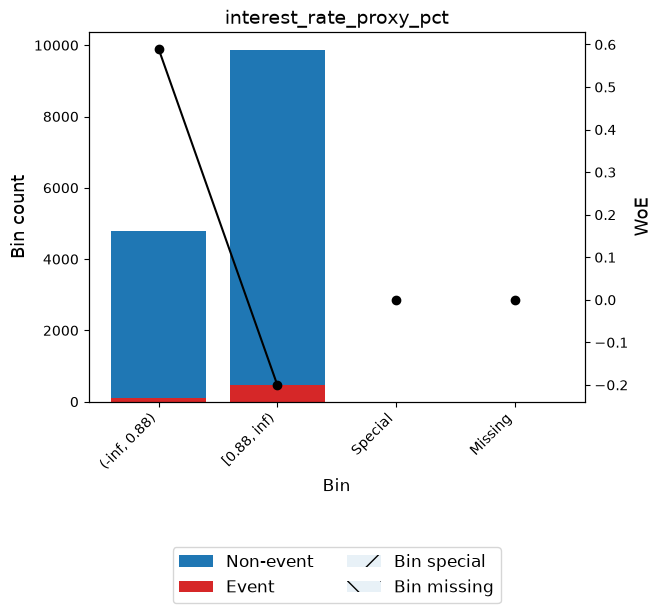

inflation_proxy_pct
Gini coefficient: 0.11400466030637424


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 2.02)",8826,0.602252,8460,366,0.041468,-0.075924,0.003596,0.000449
1,"[2.02, 2.21)",2540,0.173320,2494,46,0.018110,0.776607,0.074235,0.009053
2,"[2.21, inf)",3289,0.224429,3136,153,0.046519,-0.196129,0.009459,0.001180
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.087290,0.010683


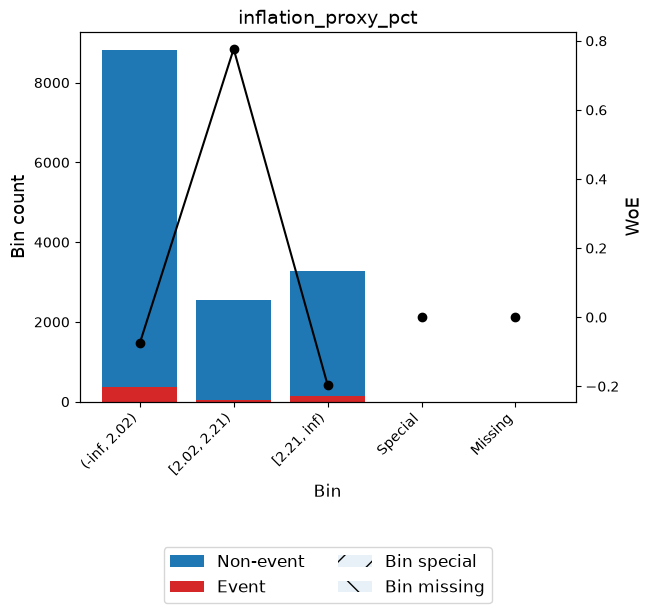

ebitda_margin
Gini coefficient: 0.1804866314526714


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.03)",2011,0.137223,1870,141,0.070114,-0.631461,0.073779,0.009072
1,"[0.03, 0.06)",3002,0.204845,2851,151,0.050300,-0.27825,0.018062,0.002251
2,"[0.06, 0.08)",2109,0.143910,2030,79,0.037459,0.029948,0.000127,0.000016
3,"[0.08, 0.09)",767,0.052337,755,12,0.015645,0.925416,0.029933,0.003614
4,"[0.09, inf)",4632,0.316070,4482,150,0.032383,0.180794,0.009512,0.001187
5,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
6,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.221046,0.026925


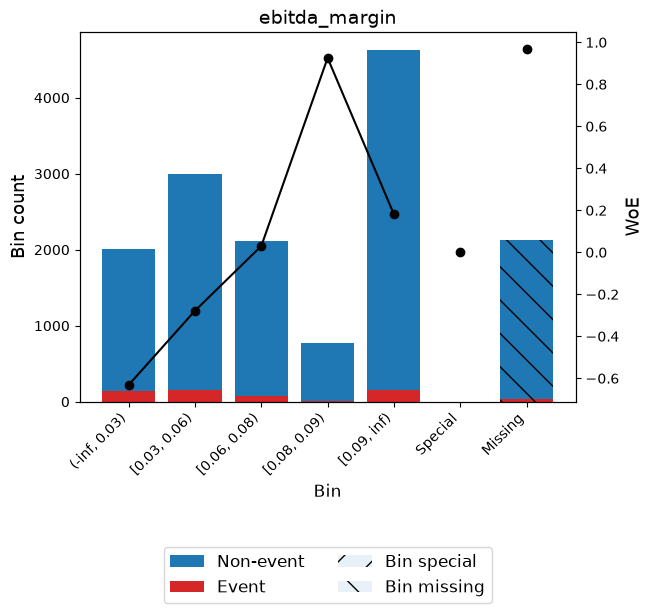

ebit_margin
Gini coefficient: 0.2024253691502791


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.02)",5105,0.348345,4820,285,0.055828,-0.388355,0.063045,0.007831
1,"[0.02, 0.08)",4258,0.290549,4092,166,0.038985,-0.011594,0.000039,0.000005
2,"[0.08, inf)",3158,0.215490,3076,82,0.025966,0.408271,0.029877,0.003709
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.182593,0.022331


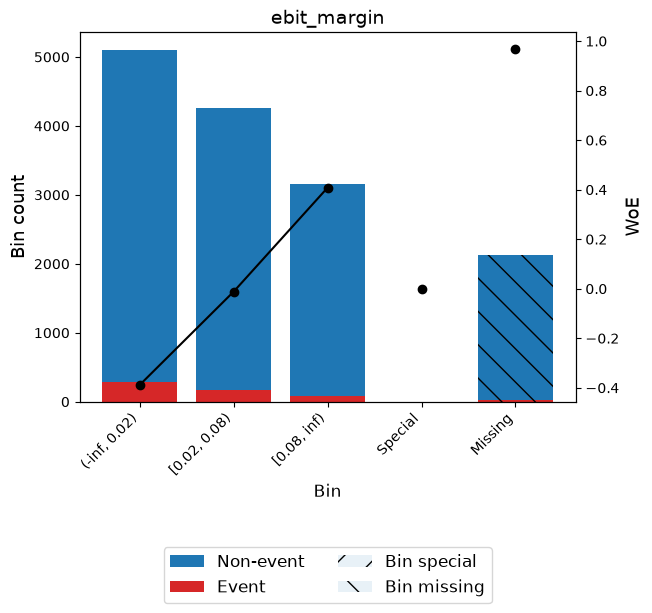

net_profit_margin
Gini coefficient: 0.16564826620272965


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -0.04)",2309,0.157557,2191,118,0.051104,-0.294966,0.015736,0.001960
1,"[-0.04, -0.02)",850,0.058001,791,59,0.069412,-0.620634,0.029968,0.003687
2,"[-0.02, 0.01)",2919,0.199181,2769,150,0.051387,-0.300789,0.020744,0.002583
3,"[0.01, 0.09)",4776,0.325896,4606,170,0.035595,0.082922,0.002157,0.000270
4,"[0.09, inf)",1667,0.113750,1631,36,0.021596,0.597035,0.031069,0.003827
5,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
6,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.189307,0.023112


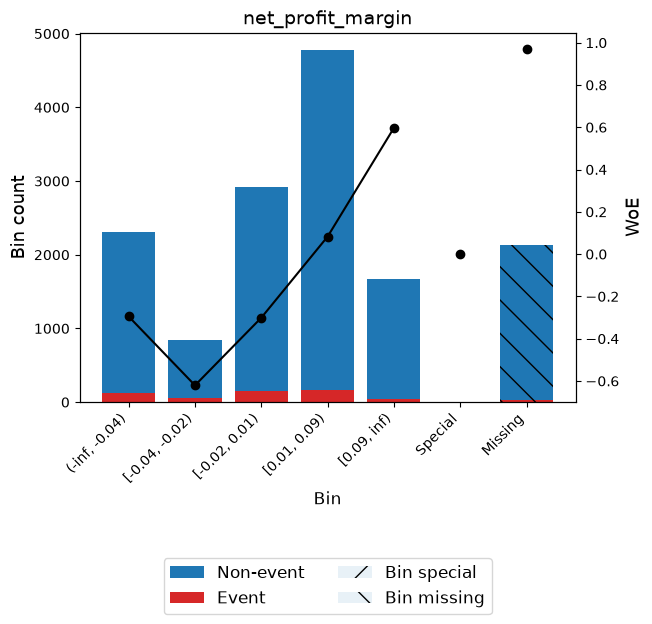

roa
Gini coefficient: 0.1830253050867685


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -0.04)",1657,0.113067,1553,104,0.062764,-0.512842,0.037874,0.004683
1,"[-0.04, 0.03)",6232,0.425247,5934,298,0.047818,-0.225035,0.023918,0.002983
2,"[0.03, inf)",4632,0.316070,4501,131,0.028282,0.320463,0.028069,0.003494
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.179493,0.021946


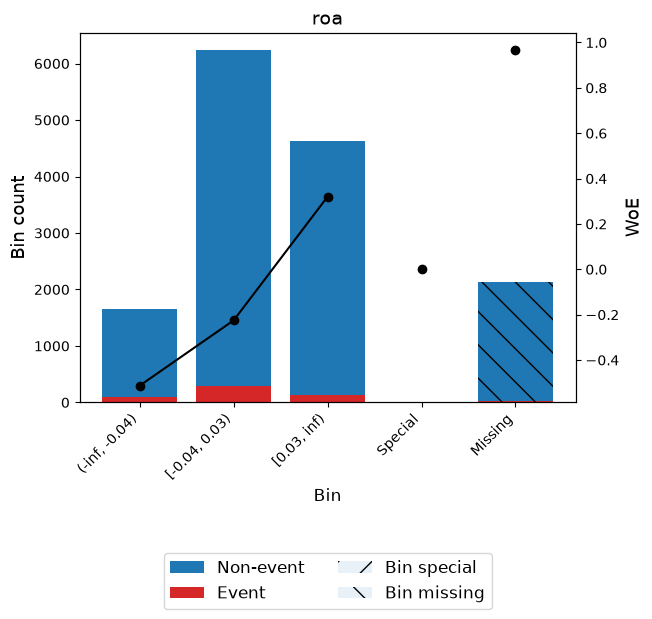

roe
Gini coefficient: 0.1687892624531302


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.06)",7426,0.506721,7038,388,0.052249,-0.318321,0.059597,0.007418
1,"[0.06, inf)",5093,0.347526,4948,145,0.028470,0.31361,0.029647,0.003691
2,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
3,Missing,2136,0.145752,2104,32,0.014981,0.969465,0.089858,0.010812
Totals,,14655,1.000000,14090,565,0.038553,,0.179102,0.021921


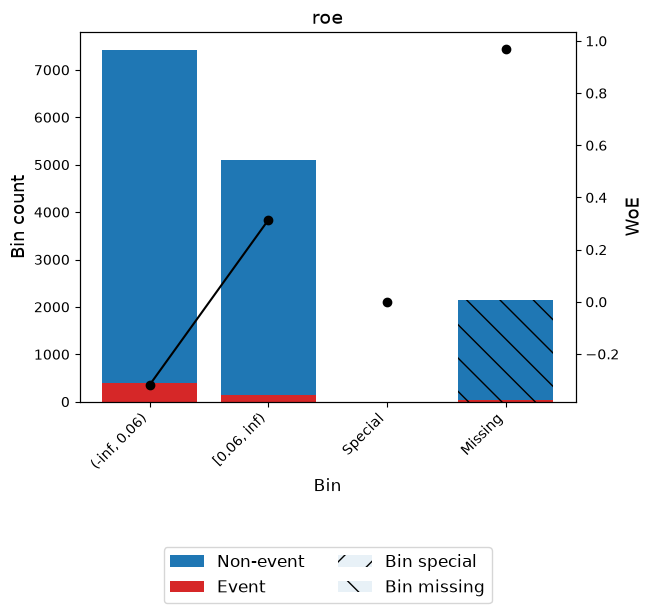

return_on_capital
Gini coefficient: 0.18420570667705105


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -0.03)",733,0.050017,674,59,0.080491,-0.780702,0.044179,0.005386
1,"[-0.03, 0.04)",6423,0.438280,6105,318,0.049510,-0.261583,0.033887,0.004224
2,"[0.04, inf)",5365,0.366087,5209,156,0.029077,0.291892,0.027318,0.003403
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.195017,0.023799


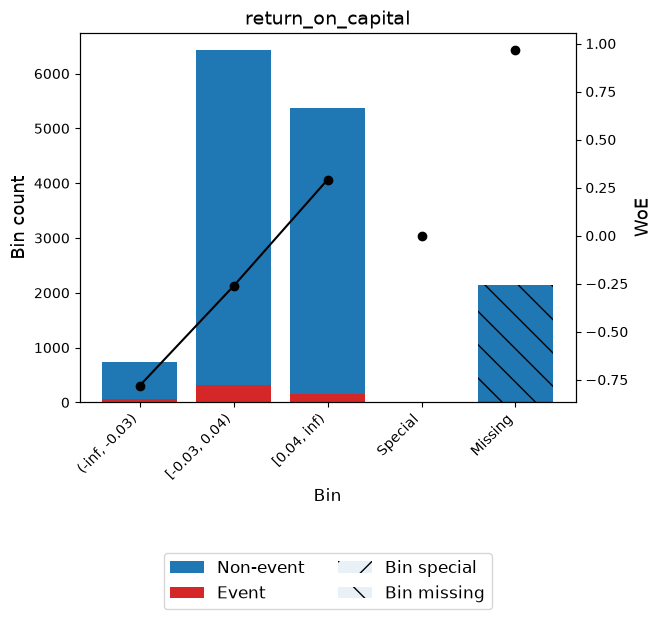

operating_cf_margin
Gini coefficient: 0.20501202761011683


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.01)",3589,0.244899,3372,217,0.060463,-0.473031,0.068472,0.008480
1,"[0.01, 0.07)",4732,0.322893,4530,202,0.042688,-0.106185,0.003825,0.000478
2,"[0.07, inf)",4200,0.286592,4086,114,0.027143,0.362728,0.032001,0.003978
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.193930,0.023722


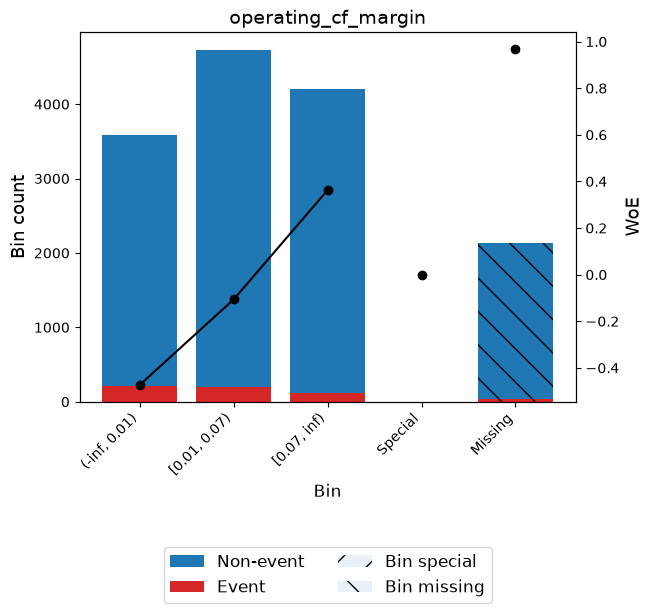

gross_margin
Gini coefficient: 0.1037269889521848


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.28)",1049,0.071580,1017,32,0.030505,0.242482,0.003769,0.000470
1,"[0.28, inf)",11472,0.782805,10971,501,0.043672,-0.12999,0.014050,0.001755
2,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
3,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.107452,0.013011


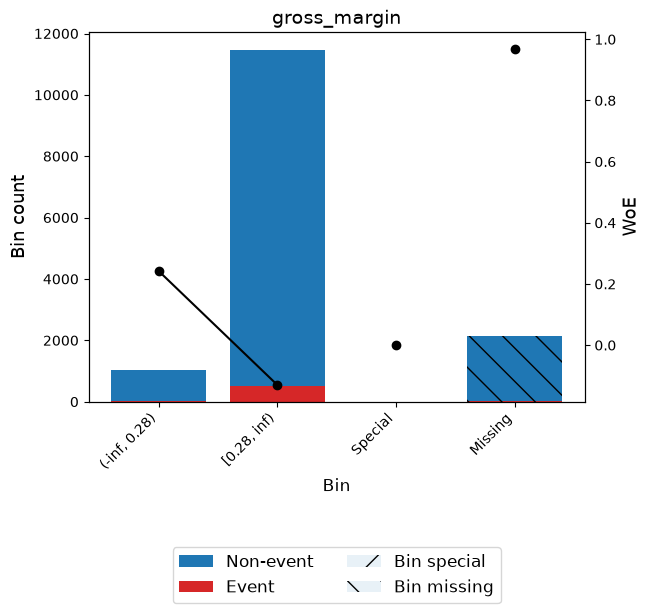

revenue_to_debt
Gini coefficient: 0.13372114786737588


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 1.50)",4567,0.311634,4383,184,0.040289,-0.045842,0.000669,0.000084
1,"[1.50, 1.66)",745,0.050836,727,18,0.024161,0.48216,0.009517,0.001178
2,"[1.66, inf)",7209,0.491914,6878,331,0.045915,-0.18243,0.017822,0.002225
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.117641,0.014272


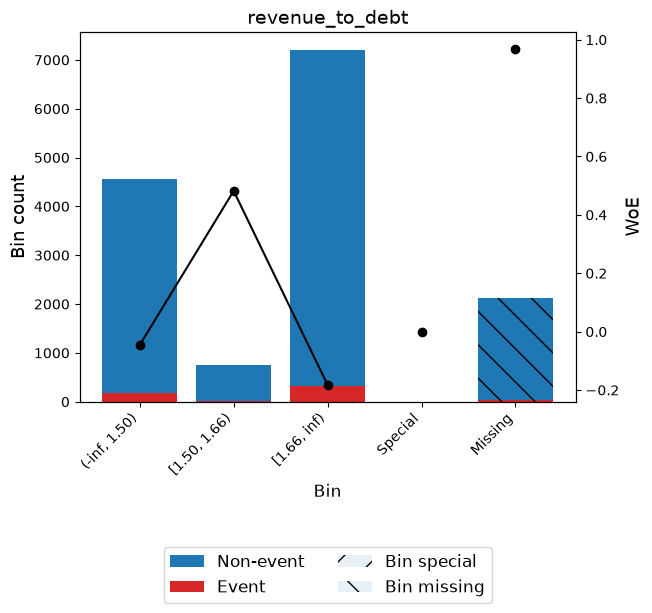

ebitda_to_assets
Gini coefficient: 0.1871282589170753


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.01)",733,0.050017,673,60,0.081855,-0.798994,0.046685,0.005685
1,"[0.01, 0.08)",6393,0.436233,6076,317,0.049585,-0.263195,0.034172,0.004259
2,"[0.08, inf)",5395,0.368134,5239,156,0.028916,0.297635,0.028489,0.003548
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.198979,0.024278


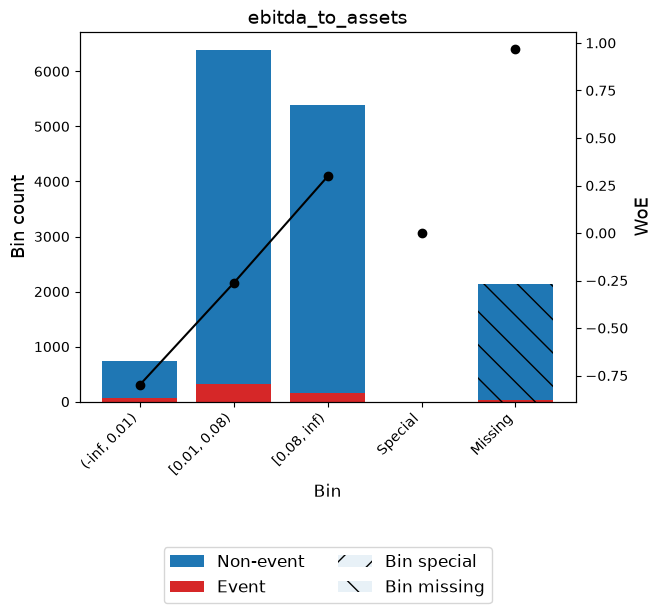

cash_return_on_assets
Gini coefficient: 0.19057110735662652


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -0.02)",742,0.050631,682,60,0.080863,-0.78571,0.045407,0.005534
1,"[-0.02, 0.05)",6745,0.460252,6414,331,0.049073,-0.252275,0.032953,0.004108
2,"[0.05, inf)",5034,0.343501,4892,142,0.028208,0.323135,0.030979,0.003856
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.198972,0.024284


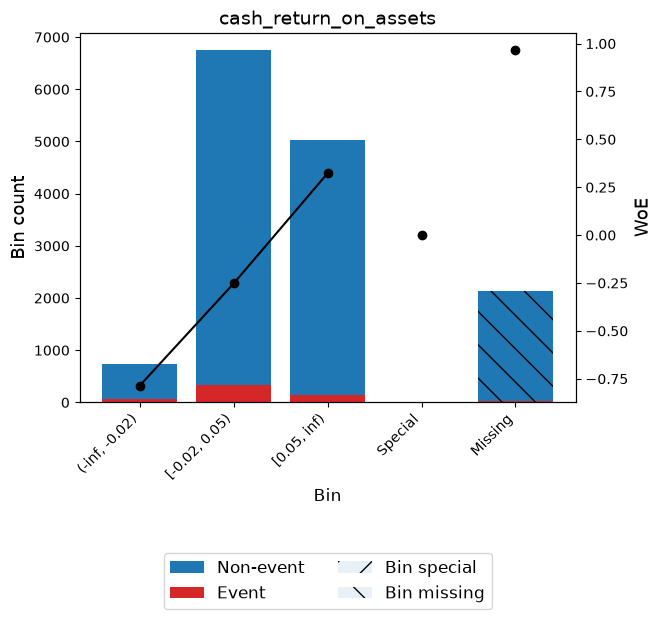

equity_ratio
Gini coefficient: 0.12306060282507514


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.18)",1728,0.117912,1660,68,0.039352,-0.02133,0.000054,0.000007
1,"[0.18, 0.26)",734,0.050085,717,17,0.023161,0.525468,0.010929,0.001351
2,"[0.26, inf)",10059,0.686387,9611,448,0.044537,-0.150525,0.016679,0.002083
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.117295,0.014226


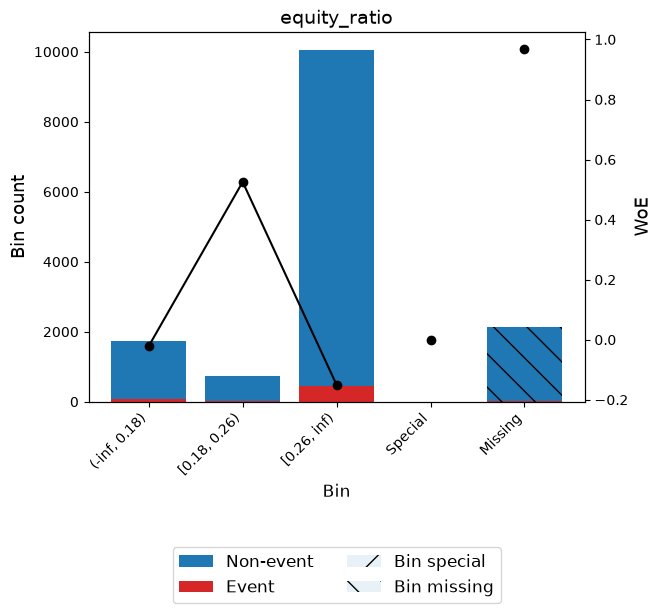

debt_to_assets
Gini coefficient: 0.12306060282507514


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.74)",10059,0.686387,9611,448,0.044537,-0.150525,0.016679,0.002083
1,"[0.74, 0.82)",734,0.050085,717,17,0.023161,0.525468,0.010929,0.001351
2,"[0.82, inf)",1728,0.117912,1660,68,0.039352,-0.02133,0.000054,0.000007
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.117295,0.014226


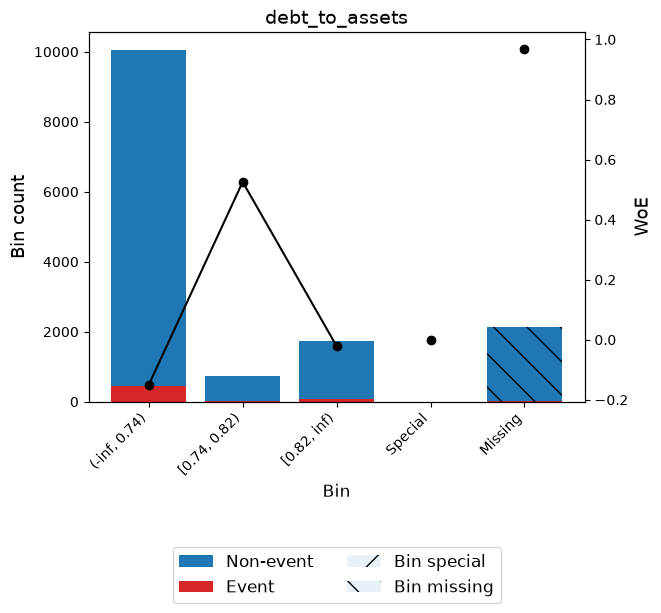

debt_to_equity
Gini coefficient: 0.11770765684568851


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 2.00)",9889,0.674787,9467,422,0.042674,-0.105833,0.007938,0.000992
1,"[2.00, 2.87)",904,0.061685,851,53,0.058628,-0.440275,0.014709,0.001824
2,"[2.87, inf)",1726,0.117776,1668,58,0.033604,0.142543,0.002242,0.000280
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2136,0.145752,2104,32,0.014981,0.969465,0.089858,0.010812
Totals,,14655,1.000000,14090,565,0.038553,,0.114747,0.013908


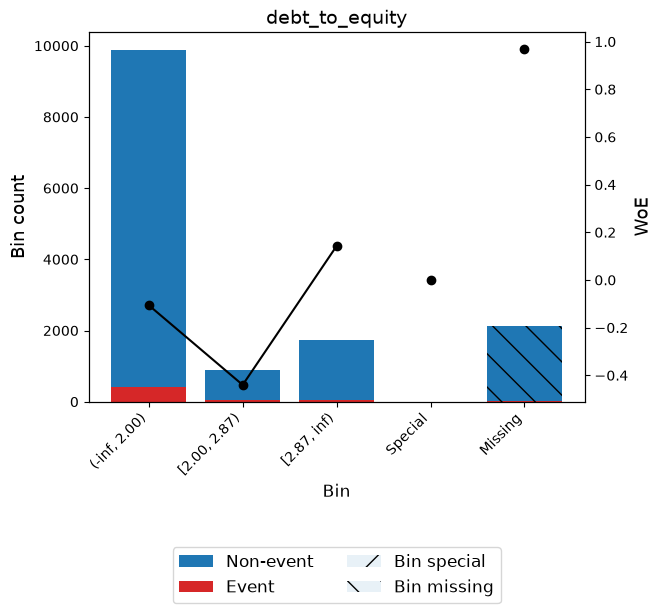

net_debt_to_ebitda
Gini coefficient: 0.16165183366097824


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -0.65)",733,0.050017,684,49,0.066849,-0.580257,0.022155,0.002731
1,"[-0.65, 1.52)",1996,0.136199,1915,81,0.040581,-0.053371,0.000398,0.000050
2,"[1.52, 3.05)",1745,0.119072,1702,43,0.024642,0.461964,0.020645,0.002558
3,"[3.05, inf)",8031,0.548004,7672,359,0.044702,-0.154385,0.014033,0.001752
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,2150,0.146708,2117,33,0.015349,0.944853,0.086777,0.010461
Totals,,14655,1.000000,14090,565,0.038553,,0.144007,0.017552


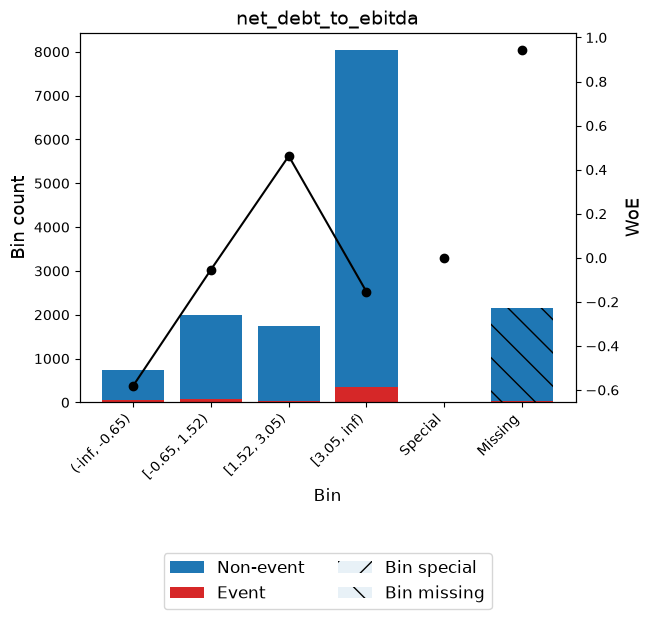

debt_to_ebitda
Gini coefficient: 0.15400265047074102


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.89)",733,0.050017,687,46,0.062756,-0.512702,0.016744,0.002070
1,"[0.89, 2.67)",1869,0.127533,1801,68,0.036383,0.060195,0.000449,0.000056
2,"[2.67, 3.55)",1005,0.068577,984,21,0.020896,0.630709,0.020604,0.002534
3,"[3.55, 41.22)",8046,0.549028,7701,345,0.042878,-0.110834,0.007100,0.000887
4,"[41.22, inf)",852,0.058137,800,52,0.061033,-0.483027,0.017030,0.002108
5,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
6,Missing,2150,0.146708,2117,33,0.015349,0.944853,0.086777,0.010461
Totals,,14655,1.000000,14090,565,0.038553,,0.148705,0.018116


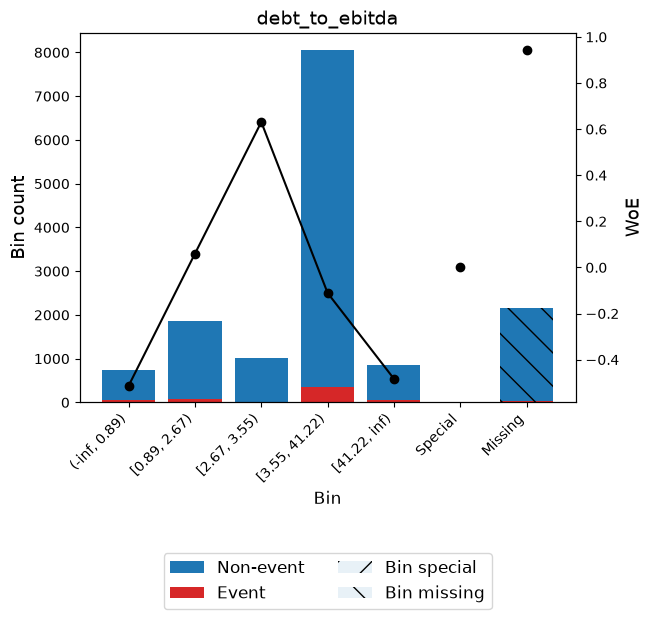

net_debt_to_assets
Gini coefficient: 0.1241328501353498


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.48)",7837,0.534766,7487,350,0.044660,-0.153405,0.013515,0.001688
1,"[0.48, 0.55)",912,0.062231,892,20,0.021930,0.581339,0.016225,0.002000
2,"[0.55, inf)",3772,0.257387,3609,163,0.043213,-0.118959,0.003849,0.000481
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.123221,0.014954


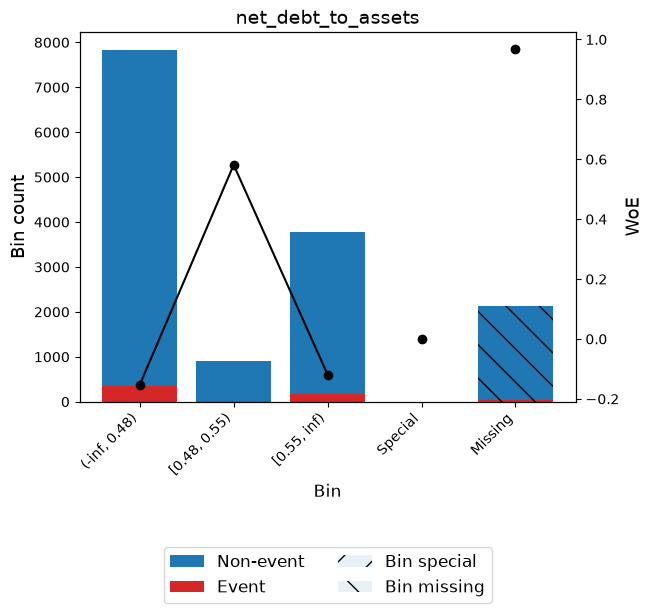

equity_to_debt
Gini coefficient: 0.12306060282507514


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.22)",1728,0.117912,1660,68,0.039352,-0.02133,0.000054,0.000007
1,"[0.22, 0.35)",734,0.050085,717,17,0.023161,0.525468,0.010929,0.001351
2,"[0.35, inf)",10059,0.686387,9611,448,0.044537,-0.150525,0.016679,0.002083
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.117295,0.014226


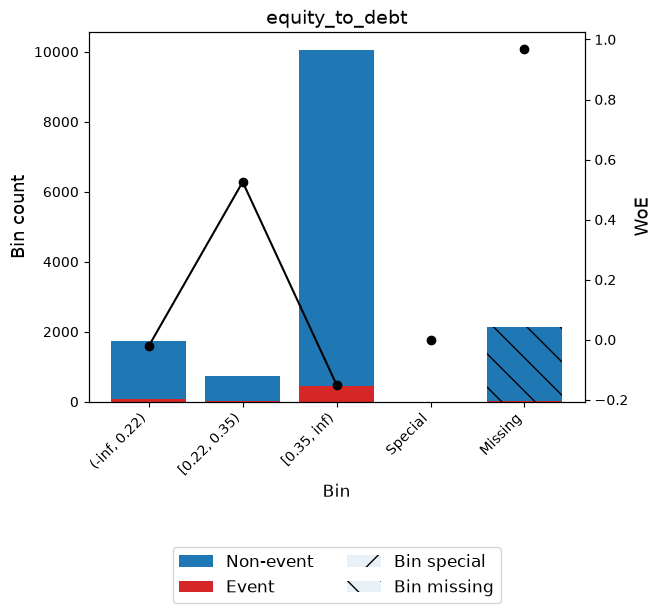

liabilities_to_equity
Gini coefficient: 0.11770765684568851


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 2.00)",9889,0.674787,9467,422,0.042674,-0.105833,0.007938,0.000992
1,"[2.00, 2.87)",904,0.061685,851,53,0.058628,-0.440275,0.014709,0.001824
2,"[2.87, inf)",1726,0.117776,1668,58,0.033604,0.142543,0.002242,0.000280
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2136,0.145752,2104,32,0.014981,0.969465,0.089858,0.010812
Totals,,14655,1.000000,14090,565,0.038553,,0.114747,0.013908


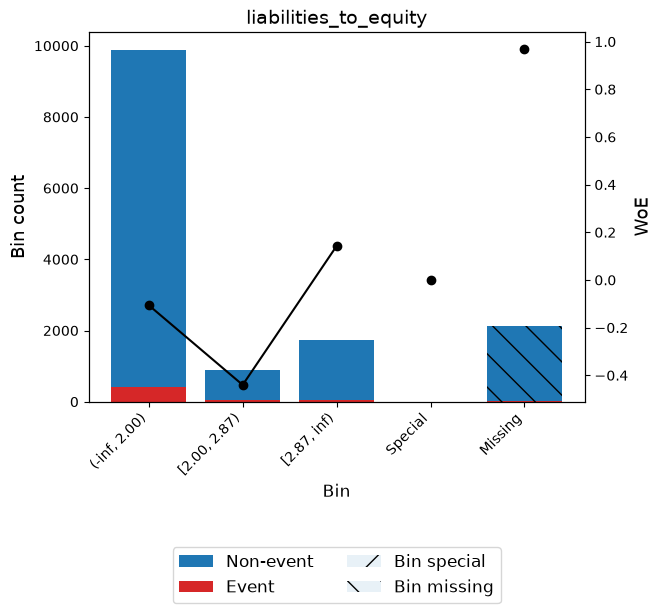

current_ratio
Gini coefficient: 0.1292774012825264


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 1.64)",6367,0.434459,6100,267,0.041935,-0.087599,0.003472,0.000434
1,"[1.64, 1.79)",816,0.055681,796,20,0.024510,0.467472,0.009862,0.001222
2,"[1.79, inf)",5338,0.364244,5092,246,0.046085,-0.1863,0.013788,0.001721
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.116754,0.014162


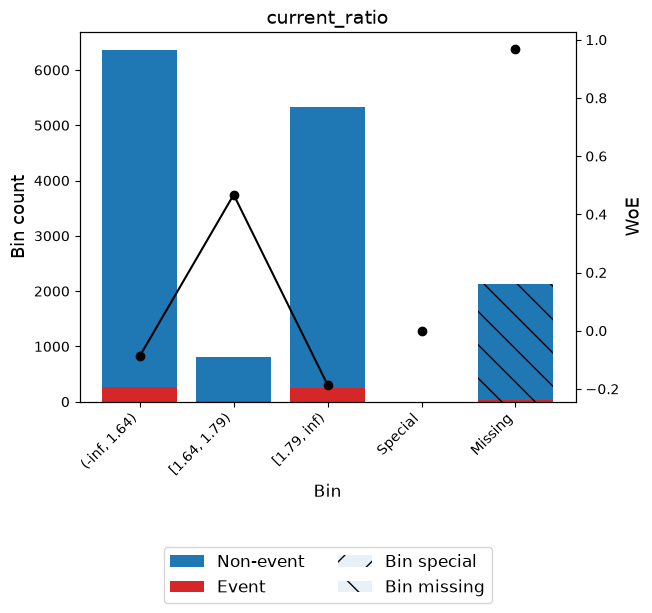

cash_ratio
Gini coefficient: 0.13638418008127262


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.48)",7323,0.499693,6984,339,0.046293,-0.191018,0.019929,0.002487
1,"[0.48, 0.65)",1350,0.092119,1314,36,0.026667,0.380917,0.011253,0.001398
2,"[0.65, inf)",3848,0.262573,3690,158,0.041060,-0.065608,0.001165,0.000146
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.121979,0.014817


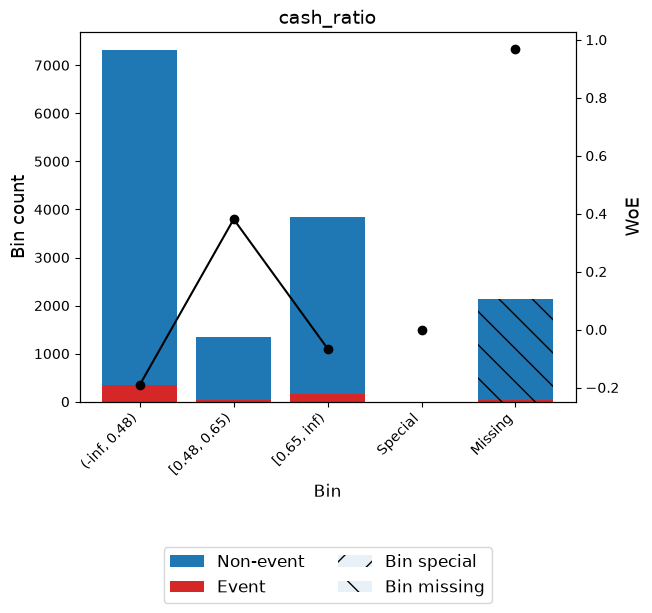

working_capital_to_assets
Gini coefficient: 0.13395780601317697


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.14)",6670,0.455135,6390,280,0.041979,-0.088695,0.003731,0.000466
1,"[0.14, 0.17)",935,0.063801,912,23,0.024599,0.463751,0.011139,0.001380
2,"[0.17, inf)",4916,0.335449,4686,230,0.046786,-0.20214,0.015060,0.001879
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.119562,0.014511


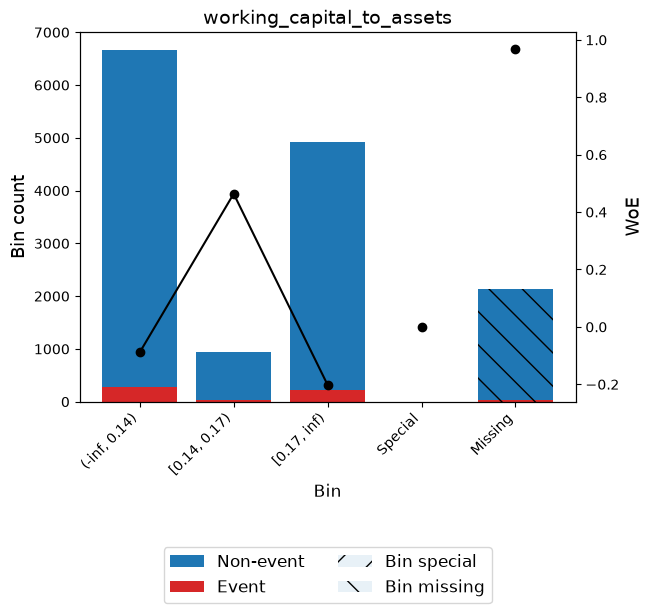

cash_to_assets
Gini coefficient: 0.11229906354220964


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.13)",9179,0.626339,8758,421,0.045866,-0.181305,0.022402,2.796360e-03
1,"[0.13, 0.16)",737,0.050290,725,12,0.016282,0.88487,0.026737,3.237214e-03
2,"[0.16, inf)",2605,0.177755,2505,100,0.038388,0.004479,0.000004,4.448231e-07
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000e+00
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,1.078575e-02
Totals,,14655,1.000000,14090,565,0.038553,,0.138775,1.681977e-02


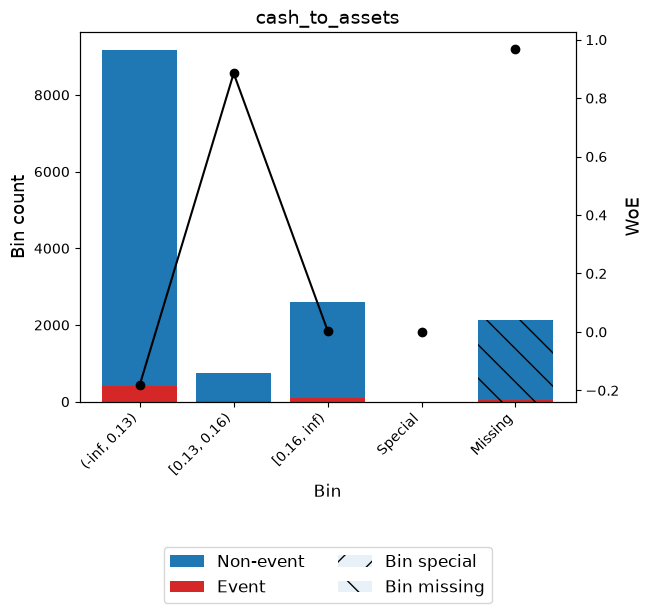

cash_to_debt
Gini coefficient: 0.14651651519624176


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.21)",7157,0.488366,6822,335,0.046807,-0.202617,0.022034,0.002750
1,"[0.21, 0.29)",1440,0.098260,1406,34,0.023611,0.505749,0.020033,0.002478
2,"[0.29, inf)",3924,0.267758,3760,164,0.041794,-0.084087,0.001968,0.000246
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.133668,0.016259


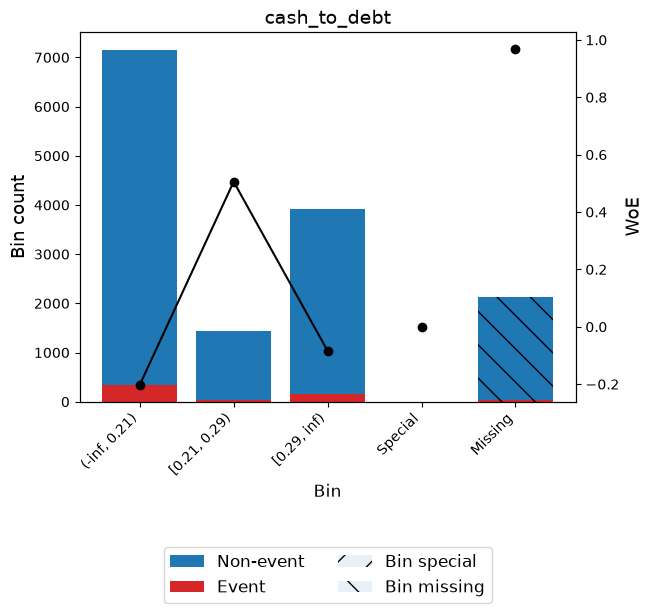

operating_cf_to_debt
Gini coefficient: 0.17614865246801537


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -0.04)",1053,0.071853,967,86,0.081671,-0.796544,0.066577,0.008109
1,"[-0.04, 0.10)",6102,0.416377,5823,279,0.045723,-0.178036,0.014338,0.001790
2,"[0.10, 0.14)",946,0.064551,926,20,0.021142,0.618747,0.018762,0.002309
3,"[0.14, inf)",4420,0.301604,4272,148,0.033484,0.14623,0.006032,0.000753
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.195341,0.023746


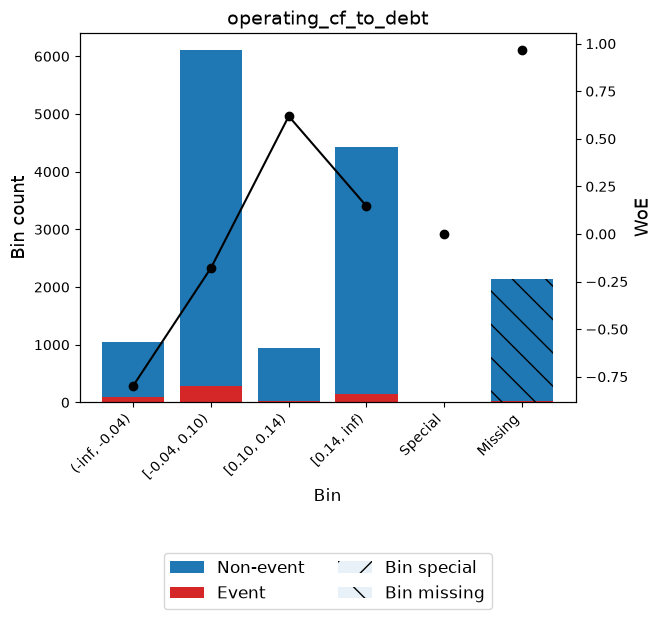

operating_cf_to_current_liabilities
Gini coefficient: 0.1662314953805184


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -0.08)",994,0.067827,913,81,0.081489,-0.794108,0.062389,0.007600
1,"[-0.08, 0.24)",6217,0.424224,5932,285,0.045842,-0.180767,0.015079,0.001882
2,"[0.24, inf)",5310,0.362334,5143,167,0.031450,0.211003,0.014651,0.001828
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.181752,0.022096


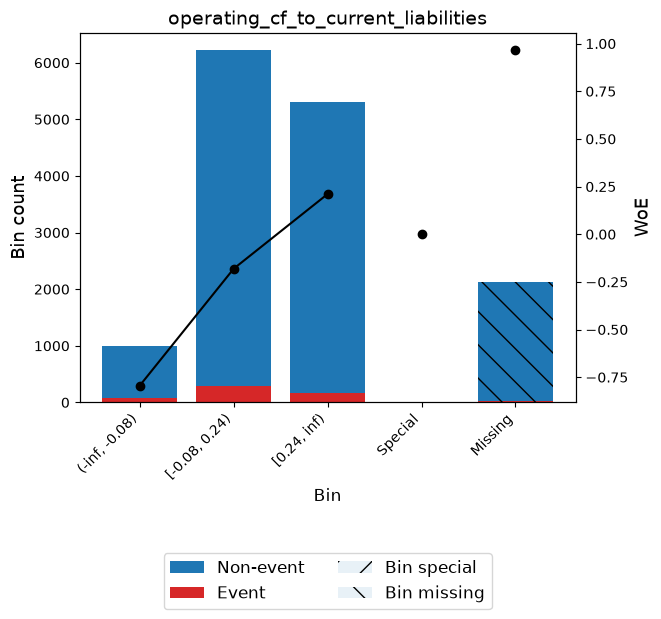

interest_coverage
Gini coefficient: 0.16599785198816708


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -0.67)",1697,0.115797,1588,109,0.064231,-0.537512,0.043117,5.325695e-03
1,"[-0.67, 1.60)",4377,0.298669,4163,214,0.048892,-0.24838,0.020691,2.579727e-03
2,"[1.60, 6.36)",3902,0.266257,3752,150,0.038442,0.003014,0.000002,3.019499e-07
3,"[6.36, inf)",2545,0.173661,2485,60,0.023576,0.507289,0.035597,4.402545e-03
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000e+00
5,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,1.078575e-02
Totals,,14655,1.000000,14090,565,0.038553,,0.189040,2.309402e-02


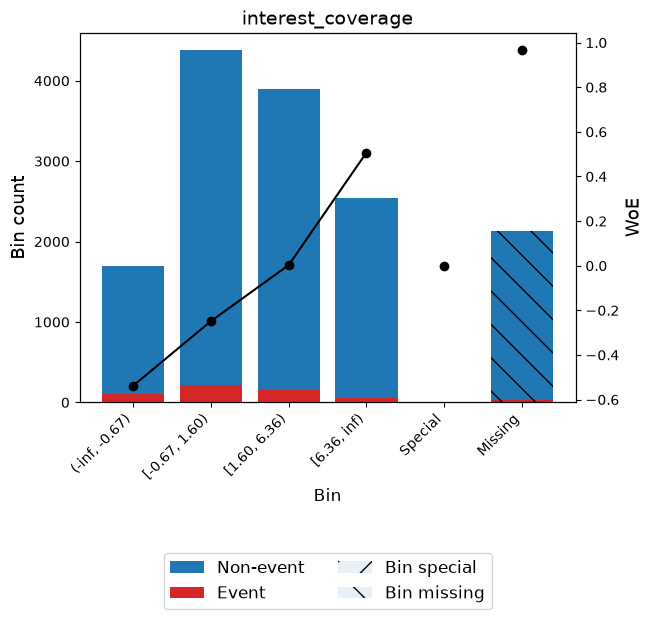

ebitda_interest_coverage
Gini coefficient: 0.15824164505046556


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.30)",742,0.050631,685,57,0.076819,-0.730027,0.038158,0.004667
1,"[0.30, 4.48)",6433,0.438963,6128,305,0.047412,-0.216083,0.022668,0.002828
2,"[4.48, 17.23)",4202,0.286728,4056,146,0.034745,0.107951,0.003180,0.000397
3,"[17.23, inf)",1144,0.078062,1119,25,0.021853,0.58492,0.020572,0.002535
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.174210,0.021213


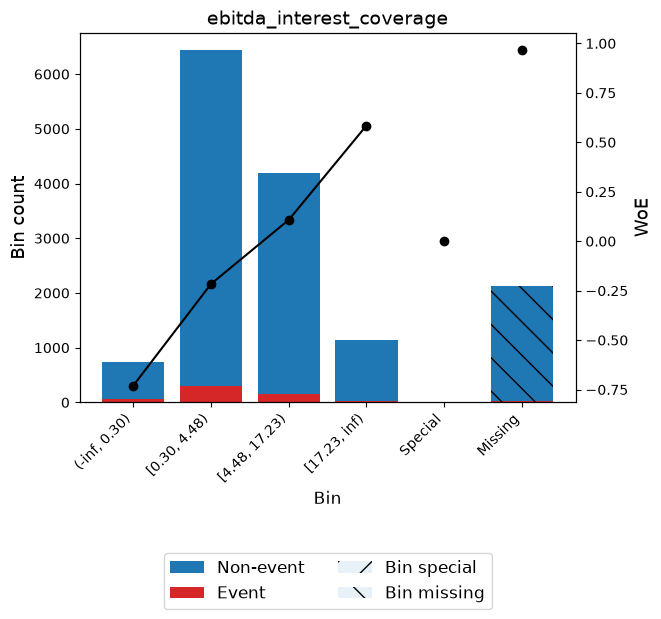

receivables_days
Gini coefficient: 0.104972710200544


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 40.52)",925,0.063118,898,27,0.029189,0.287938,0.004591,0.000572
1,"[40.52, inf)",11596,0.791266,11090,506,0.043636,-0.129132,0.014010,0.001750
2,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
3,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.108234,0.013108


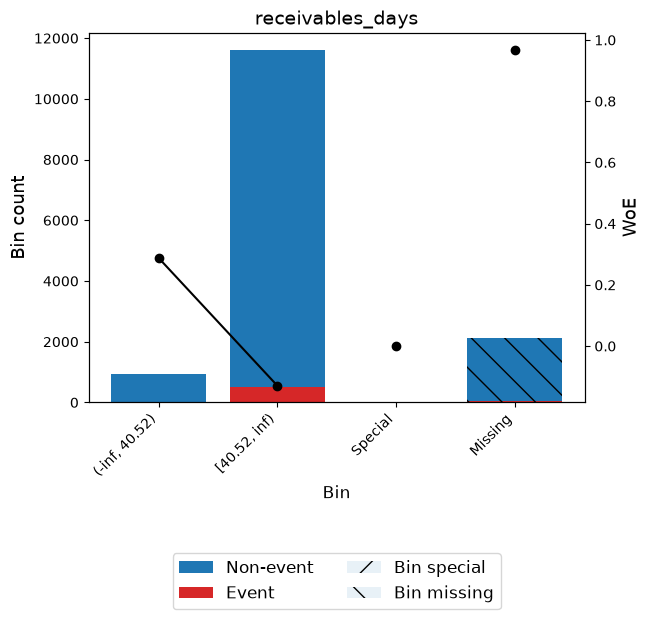

payables_days
Gini coefficient: 0.12906297694341684


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 66.14)",8256,0.563357,7905,351,0.042515,-0.10193,0.006136,7.667289e-04
1,"[66.14, 68.20)",746,0.050904,700,46,0.061662,-0.493956,0.015676,1.939799e-03
2,"[68.20, inf)",3519,0.240123,3383,136,0.038647,-0.002532,0.000002,1.925918e-07
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000e+00
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,1.078575e-02
Totals,,14655,1.000000,14090,565,0.038553,,0.111447,1.349247e-02


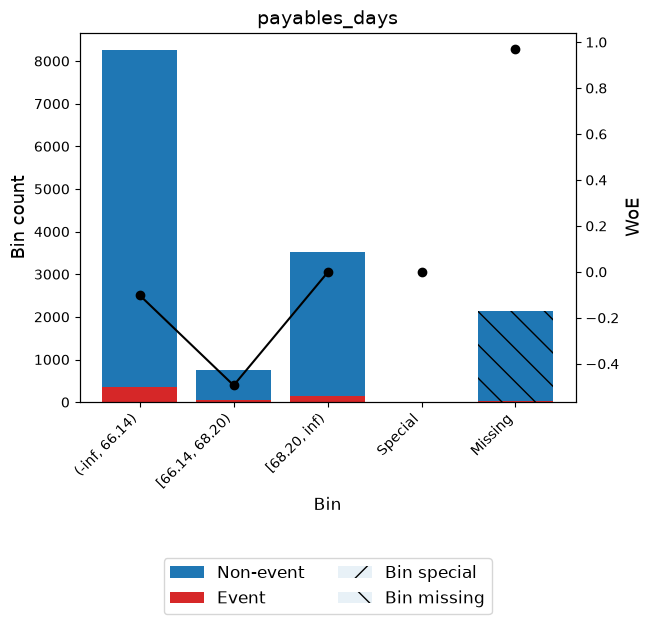

cash_conversion_cycle
Gini coefficient: 0.1199091805523278


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 11.78)",850,0.058001,809,41,0.048235,-0.234168,0.003548,0.000442
1,"[11.78, 15.87)",1602,0.109314,1556,46,0.028714,0.304837,0.008845,0.001101
2,"[15.87, inf)",10069,0.687069,9623,446,0.044294,-0.144802,0.015409,0.001924
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.117435,0.014254


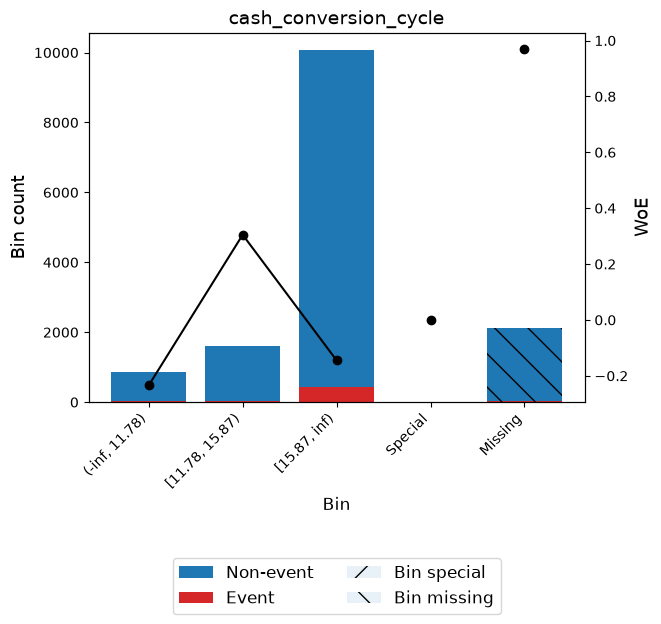

receivable_turnover
Gini coefficient: 0.13018157608798053


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 8.79)",10228,0.697919,9799,429,0.041944,-0.087816,0.005606,0.000700
1,"[8.79, 9.01)",1368,0.093347,1291,77,0.056287,-0.397028,0.017730,0.002202
2,"[9.01, inf)",925,0.063118,898,27,0.029189,0.287938,0.004591,0.000572
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.117560,0.014260


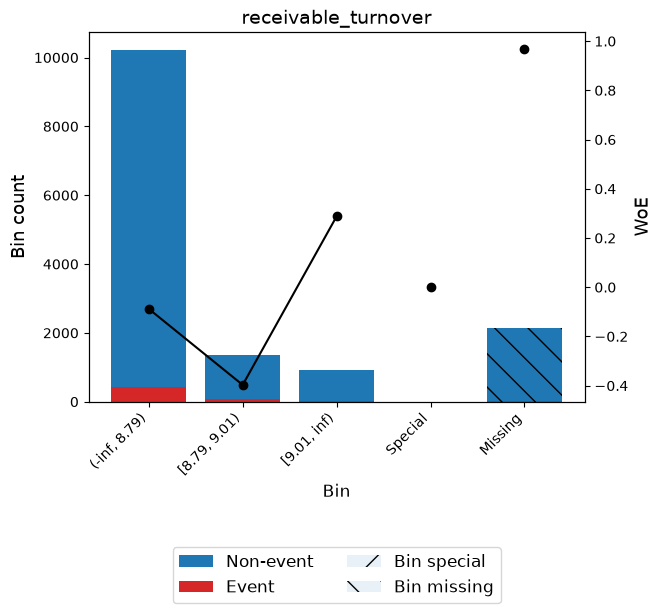

working_capital_turnover
Gini coefficient: 0.12154933204368867


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 6.07)",7574,0.516820,7244,330,0.043570,-0.127559,0.008922,0.001115
1,"[6.07, 8.21)",1448,0.098806,1406,42,0.029006,0.29444,0.007494,0.000933
2,"[8.21, inf)",3491,0.238212,3330,161,0.046119,-0.187072,0.009095,0.001135
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2142,0.146162,2110,32,0.014939,0.972312,0.090536,0.010891
Totals,,14655,1.000000,14090,565,0.038553,,0.116047,0.014074


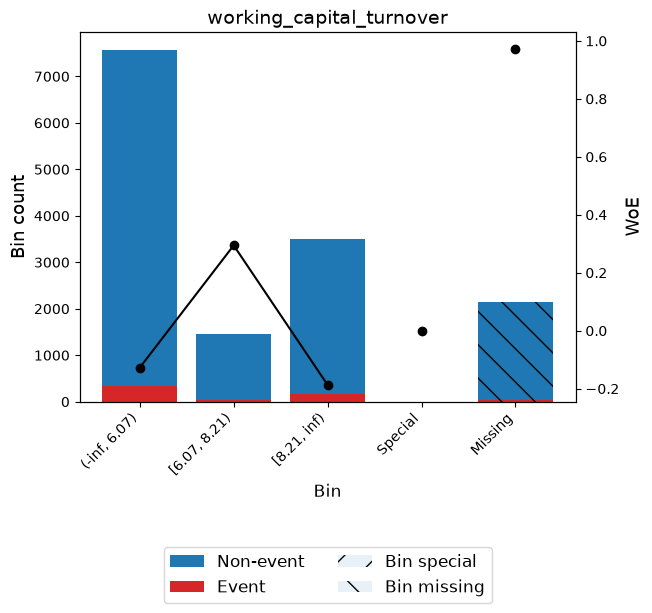

financial_debt_to_revenue
Gini coefficient: 0.13372114786737588


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.60)",7209,0.491914,6878,331,0.045915,-0.18243,0.017822,0.002225
1,"[0.60, 0.67)",745,0.050836,727,18,0.024161,0.48216,0.009517,0.001178
2,"[0.67, inf)",4567,0.311634,4383,184,0.040289,-0.045842,0.000669,0.000084
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.117641,0.014272


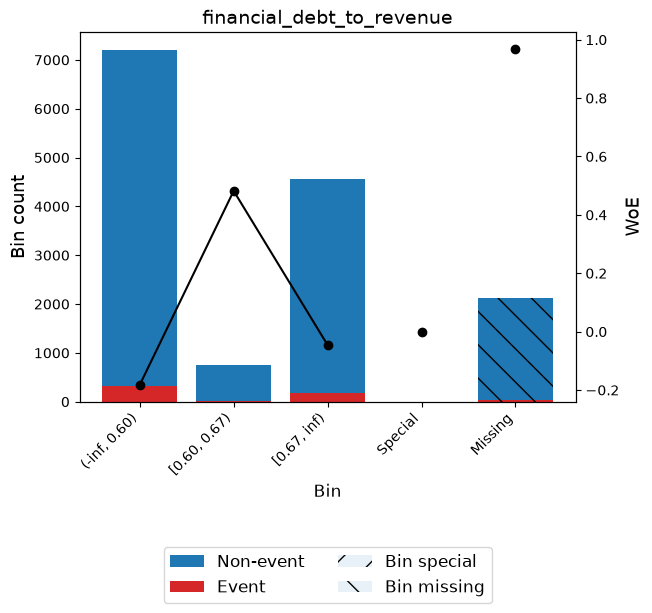

employees_log
Gini coefficient: 0.11113737854626082


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 4.80)",5883,0.401433,5624,259,0.044025,-0.138425,0.008203,0.001025
1,"[4.80, 4.99)",798,0.054452,777,21,0.026316,0.394523,0.007092,0.000881
2,"[4.99, inf)",5840,0.398499,5587,253,0.043322,-0.121587,0.006233,0.000779
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.111161,0.013470


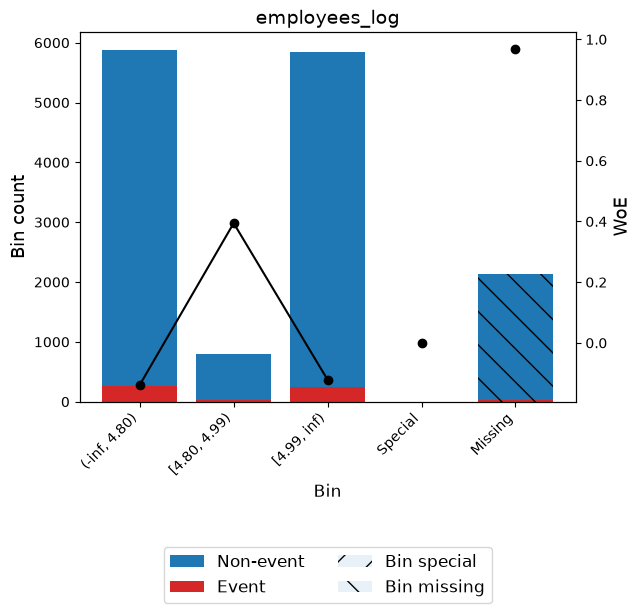

ead_to_revenue
Gini coefficient: 0.15609790411827884


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.13)",4462,0.304469,4321,141,0.031600,0.206087,0.011770,0.001469
1,"[0.13, 0.30)",6640,0.453088,6343,297,0.044729,-0.15502,0.011702,0.001461
2,"[0.30, inf)",1419,0.096827,1324,95,0.066949,-0.581859,0.043159,0.005320
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.156264,0.019036


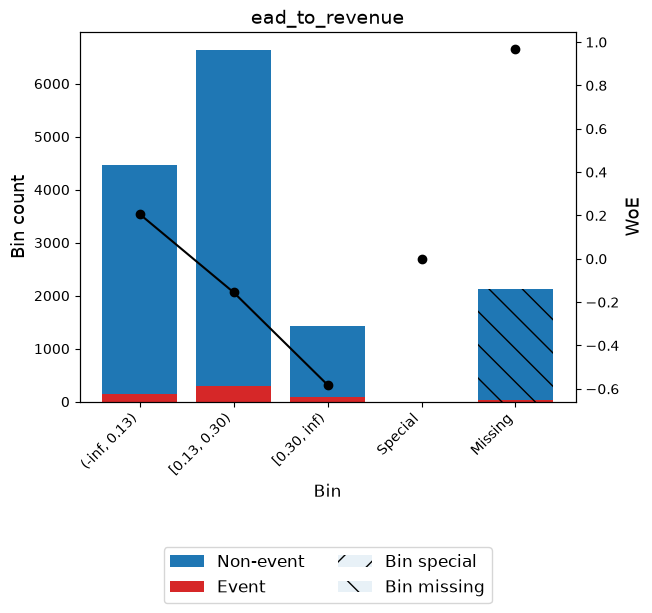

credit_limit_to_revenue
Gini coefficient: 0.10389305162137208


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.24)",5547,0.378506,5303,244,0.043988,-0.137535,0.007632,0.000953
1,"[0.24, 0.33)",3332,0.227363,3215,117,0.035114,0.097014,0.002047,0.000256
2,"[0.33, inf)",3642,0.248516,3470,172,0.047227,-0.211979,0.012327,0.001538
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,2134,0.145616,2102,32,0.014995,0.968514,0.089633,0.010786
Totals,,14655,1.000000,14090,565,0.038553,,0.111638,0.013533


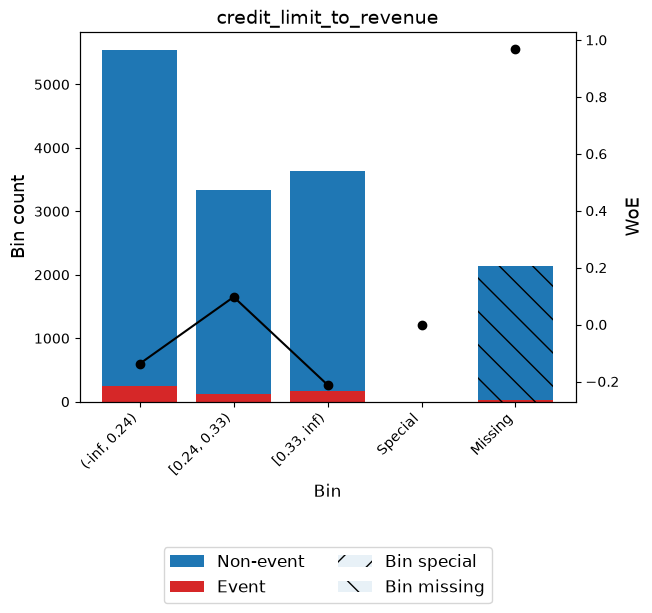

cashflow_in_to_out
Gini coefficient: 0.10519818863563568


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 1.03)",5271,0.359672,5023,248,0.047050,-0.208041,0.017152,0.002140
1,"[1.03, 1.29)",6770,0.461958,6522,248,0.036632,0.053113,0.001272,0.000159
2,"[1.29, inf)",2614,0.178369,2545,69,0.026396,0.391385,0.022896,0.002844
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.041320,0.005143


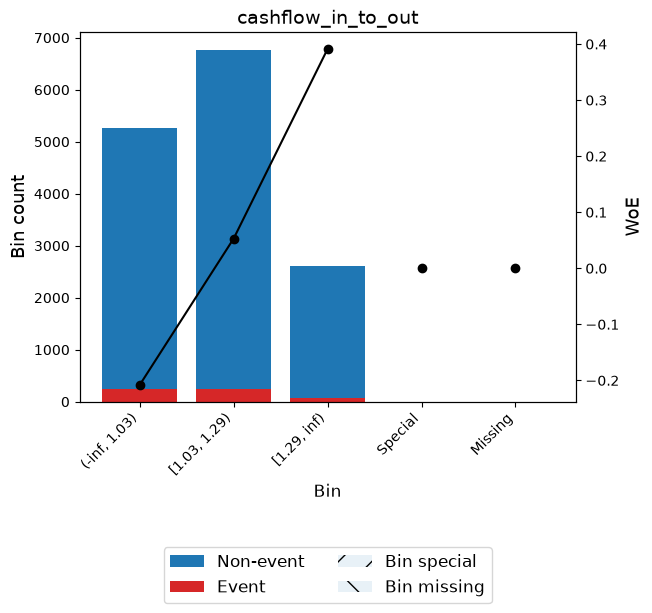

cash_to_ead
Gini coefficient: 0.1393182888761879


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.35)",4826,0.329307,4575,251,0.052010,-0.313486,0.037477,0.004666
1,"[0.35, 1.63)",8107,0.553190,7832,275,0.033921,0.132807,0.009181,0.001147
2,"[1.63, inf)",1722,0.117503,1683,39,0.022648,0.548377,0.027649,0.003413
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,14655,1.000000,14090,565,0.038553,,0.074307,0.009226


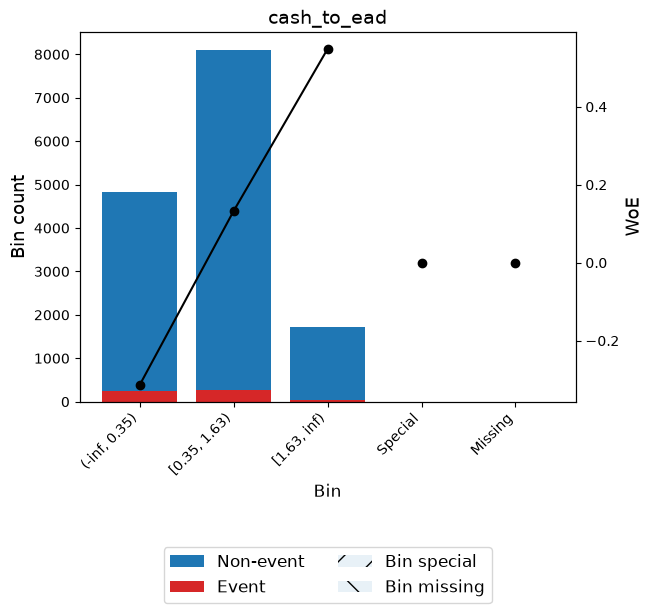

In [8]:
binning_var = {}

for v in var:
    binning = optb.OptimalBinning(name=v, dtype= "categorical" if train_info.loc[v, "dtypes"] == "str" else "numerical", max_pvalue=0.05)
    binning.fit(train[v], train["default_12m"])
    table = binning.binning_table.build()
    woe = binning.transform(train[v], metric="woe")
    gini = 2*roc_auc_score(1 - train["default_12m"], woe) - 1
    if len(table.index) <= 4 or gini < 1e-1:
        continue
    print(v)
    print("Gini coefficient:", gini)
    display(table)
    binning.binning_table.plot(show_bin_labels=True)
    binning_var[v] = binning
    

In [9]:
with open("Pickle/binning_var.pkl", "wb") as f:
    pickle.dump(binning_var, f)